In [1]:
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

from chlforecast import archive, config, forecast, scoring
from chlforecast import features as F

OUTPUT = config.PROCESSED

bundle = joblib.load(config.MODEL_PATH)
model_mask = bundle["model_mask"]
mask = model_mask.values == 1
latitude = model_mask.latitude.values
longitude = model_mask.longitude.values
monthly_log_clim = bundle["monthly_log_climatology"].values
horizons = [int(h) for h in bundle["forecast_horizons_days"]]

print(f"Model inputs ({len(bundle['feature_names'])}): {bundle['feature_names']}")
print(f"Trained on issue dates {bundle['training_issue_date_range']}; climatology {bundle['climatology_period']}")
print(f"Modelled pixels: {int(mask.sum()):,}")


Model inputs (18): ['season_sin', 'season_cos', 'chl_latest', 'chl_age_days', 'chl_mean_7d', 'chl_observations_7d', 'latitude_deg', 'longitude_deg', 'chl_clim_log', 'sst_c', 'sst_observed', 'chl_nbr5_yesterday', 'chl_nbr15_7d', 'chl_trend_log', 'chl_anomaly_log', 'sst_anomaly', 'sst_change_7d', 'coast_distance_km']
Trained on issue dates ['2017-01-01', '2024-12-24']; climatology 2017–2023
Modelled pixels: 12,190


In [2]:
# Live data comes from the local archive written by step 08 (run it first).
chl_dates, chl_values, chl_retrieved = archive.load("chl", latitude, longitude)
l4_dates, l4_values, _ = archive.load("chl_l4", latitude, longitude)
sst_dates, sst_values, sst_retrieved = archive.load("sst", latitude, longitude)

# The same quality rule as in training.
chl_values = F.quality_control(chl_values, minimum=config.MIN_PLAUSIBLE_CHL)
l4_values = F.quality_control(l4_values, minimum=config.MIN_PLAUSIBLE_CHL)

display(archive.holdings())


,Days archived,Later versions kept,First,Last,Missing days
Source,,,,,
chl,10,0,2026-10-10,2026-10-19,None
chl_l4,13,0,2026-10-07,2026-10-19,None
sst,31,0,2026-09-20,2026-10-20,None


In [3]:
# One daily calendar: from the first archived chlorophyll day to the day after
# the last one (the next issue day), or the last temperature day if later.
start = chl_dates[0]
end = max(chl_dates[-1] + pd.Timedelta(days=config.CHL_LAG_DAYS), sst_dates[-1])
dates = pd.date_range(start, end, freq="D")


def on_calendar(source_dates, values):
    out = np.full((len(dates),) + values.shape[1:], np.nan, dtype="float32")
    keep = source_dates.isin(dates)
    out[dates.get_indexer(source_dates[keep])] = values[keep]
    return out


chl = on_calendar(chl_dates, chl_values)
sst = on_calendar(sst_dates, sst_values)
l4 = on_calendar(l4_dates, l4_values)

# The model's 11 inputs for every issue day, built exactly as in step 04.
inputs = F.model_inputs(chl, sst, dates, mask, monthly_log_clim, bundle["monthly_sst_climatology"].values,
                        bundle["coast_distance_km"].values, latitude, longitude)


# An issue day has a complete history when all of its 7-day window is archived.
first_complete = chl_dates[0] + pd.Timedelta(days=config.CHL_HISTORY_DAYS + config.CHL_LAG_DAYS - 1)
complete = np.asarray(dates >= first_complete)

display(pd.Series({
    "Calendar": f"{dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d}",
    "Chlorophyll days archived": f"{len(chl_dates)} ({chl_dates[0]:%Y-%m-%d} to {chl_dates[-1]:%Y-%m-%d})",
    "First issue day with complete history": f"{first_complete:%Y-%m-%d}",
    "Issue days with complete history": int(complete.sum()),
    "Latest issue day": f"{dates[-1]:%Y-%m-%d}",
}).to_frame("Value"))

,Value
Calendar,2026-10-10 to 2026-10-20
Chlorophyll days archived,10 (2026-10-10 to 2026-10-19)
First issue day with complete history,2026-10-17
Issue days with complete history,4
Latest issue day,2026-10-20


In [4]:
# Today's live forecast: the latest issue day in the calendar.
k = len(dates) - 1
issue_day = dates[k]
day_inputs = {name: values[k:k + 1] for name, values in inputs.items()}
live = {h: forecast.model_forecast(bundle, day_inputs, [issue_day], h)[0] for h in horizons}

today = pd.Timestamp(datetime.now(timezone.utc).date())
if issue_day < today:
    print(f"NOTE: the latest issue day is {issue_day:%Y-%m-%d}, before today ({today:%Y-%m-%d}). "
          "Run step 08 first to archive the newest data.")

has_history = np.isfinite(day_inputs["chl_latest"][0]) & mask
ages = day_inputs["chl_age_days"][0][has_history]
display(pd.Series({
    "Issue day": f"{issue_day:%Y-%m-%d} at {config.FORECAST_ISSUE_TIME_UTC} UTC",
    "Newest chlorophyll used": f"{issue_day - pd.Timedelta(days=config.CHL_LAG_DAYS):%Y-%m-%d}",
    "Pixels with chlorophyll history": f"{int(has_history.sum()):,} of {int(mask.sum()):,}",
    "Pixels on the climatology fallback": int((mask & ~has_history).sum()),
    "Latest observation 1 day old": f"{100 * np.mean(ages == 1):.1f}%",
    "Oldest observation used (days)": int(ages.max()) if ages.size else None,
    "Pixels with last night's temperature": f"{int((day_inputs['sst_observed'][0] == 1).sum()):,}",
}).to_frame("Value"))


NOTE: the latest issue day is 2026-10-20, before today (2026-10-21). Run step 08 first to archive the newest data.


,Value
Issue day,2026-10-20 at 20:30 UTC
Newest chlorophyll used,2026-10-19
Pixels with chlorophyll history,"12,185 of 12,190"
Pixels on the climatology fallback,5
Latest observation 1 day old,0.0%
Oldest observation used (days),7
Pixels with last night's temperature,"11,139"


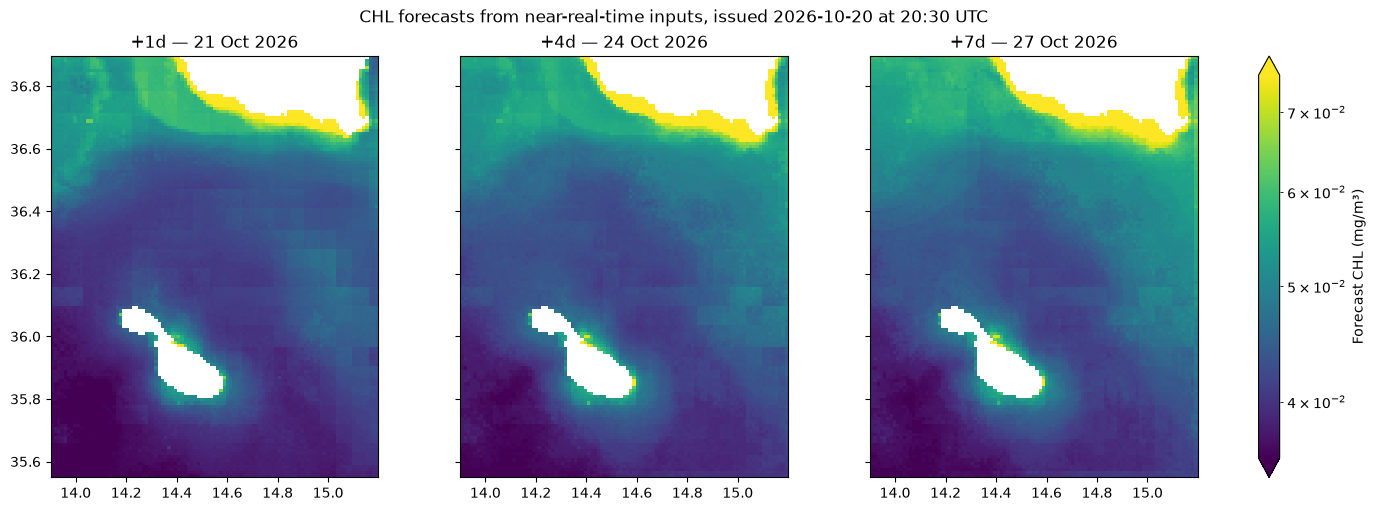

Saved today's forecast, inputs and map to: /Users/alangatt/git/mcast.pages.chl_prediction/experiment_v2/data/processed/nrt_forecasts/20261021T054525Z


In [5]:
# Map and save today's forecast, with the inputs it used.
run = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
forecast_dir = OUTPUT / "nrt_forecasts" / run
forecast_dir.mkdir(parents=True, exist_ok=True)

target_dates = [issue_day + pd.Timedelta(days=h) for h in horizons]
values = np.stack([live[h] for h in horizons]).astype("float32")
vmin, vmax = np.nanpercentile(values, [2, 98])
fig, axes = plt.subplots(1, len(horizons), figsize=(14, 5), sharex=True, sharey=True, constrained_layout=True)
for ax, h, target_date in zip(axes, horizons, target_dates):
    image = ax.pcolormesh(longitude, latitude, live[h], cmap="viridis", norm=LogNorm(vmin=vmin, vmax=vmax))
    ax.set_title(f"+{h}d — {target_date:%d %b %Y}")
    ax.set_aspect(1 / np.cos(np.deg2rad(latitude.mean())))
fig.colorbar(image, ax=list(axes), label="Forecast CHL (mg/m³)", extend="both")
fig.suptitle(f"CHL forecasts from near-real-time inputs, issued {issue_day:%Y-%m-%d} at {config.FORECAST_ISSUE_TIME_UTC} UTC")
plt.show()

grid_coords = {"latitude": model_mask.latitude, "longitude": model_mask.longitude}
used = [chl_retrieved.get(f"{issue_day - pd.Timedelta(days=config.CHL_LAG_DAYS):%Y-%m-%d}"),
        sst_retrieved.get(f"{issue_day:%Y-%m-%d}")]
provenance = {
    "issue_date": f"{issue_day:%Y-%m-%d}",
    "nominal_issue_time_utc": config.FORECAST_ISSUE_TIME_UTC,
    "retrieval_finished_utc": max(u for u in used if u) if any(used) else "",
    "input_source": "Copernicus Marine NRT observations, local archive (step 08)",
    "model_training_source": "Copernicus Marine MY observations",
    "source_datasets_json": json.dumps({"CHL": archive.SOURCES["chl"]["dataset_id"], "SST": archive.SOURCES["sst"]["dataset_id"]}),
    "source_versions_json": json.dumps({
        "CHL": xr.open_dataset(sorted((config.ARCHIVE_DIR / "chl").glob("*.nc"))[-1]).attrs.get("source_dataset_version", ""),
        "SST": xr.open_dataset(sorted((config.ARCHIVE_DIR / "sst").glob("*.nc"))[-1]).attrs.get("source_dataset_version", ""),
    }),
    "feature_names_json": json.dumps(bundle["feature_names"]),
    "model_file": config.MODEL_PATH.name,
    "raw_snapshot_directory": str(config.ARCHIVE_DIR),
}

saved_forecast = xr.Dataset(
    {
        "chl_forecast": (("horizon", "latitude", "longitude"), values),
        "chl_history_available": (("latitude", "longitude"), has_history.astype("uint8")),
        "sst_available": (("latitude", "longitude"), (day_inputs["sst_observed"][0] == 1).astype("uint8")),
        "model_mask": (("latitude", "longitude"), mask.astype("uint8")),
    },
    coords={"horizon": horizons, **grid_coords, "time": issue_day.to_datetime64(),
            "target_date": ("horizon", [d.to_datetime64() for d in target_dates])},
    attrs=provenance,
)
saved_forecast["chl_forecast"].attrs["units"] = "milligram m^-3"
saved_inputs = xr.Dataset(
    {name: (("latitude", "longitude"), np.broadcast_to(day_inputs[name][0], mask.shape).astype("float32"))
     for name in bundle["feature_names"]},
    coords={**grid_coords, "time": issue_day.to_datetime64()},
    attrs={**provenance,
           "time_meaning": "Forecast issue date",
           "chl_latest_eligible_date": f"{issue_day - pd.Timedelta(days=config.CHL_LAG_DAYS):%Y-%m-%d}",
           "sst_date": f"{issue_day - pd.Timedelta(days=config.SST_LAG_DAYS):%Y-%m-%d}"},
)
for filename, dataset in [("chl_forecasts.nc", saved_forecast), ("nrt_features.nc", saved_inputs)]:
    dataset.to_netcdf(forecast_dir / filename,
                      encoding={n: {"zlib": True, "complevel": 4} for n, v in dataset.data_vars.items() if v.ndim > 0})
fig.savefig(forecast_dir / "chl_forecasts.png", dpi=200, bbox_inches="tight")
print(f"Saved today's forecast, inputs and map to: {forecast_dir}")


In [6]:
# Score past live forecasts against what the satellite later observed.
# Only issue days with a complete history window count, as in training.
rows = []
interval_rows = []
evaluation = {}
for h in horizons:
    issue_index = np.flatnonzero(complete & (np.arange(len(dates)) + h < len(dates)))
    issue_index = issue_index[dates[issue_index] + pd.Timedelta(days=h) <= chl_dates[-1]]
    if issue_index.size == 0:
        rows.append({"Horizon": f"+{h}d", "Method": "—", "Scored issue days": 0})
        continue
    model = forecast.model_forecast(bundle, inputs, dates, h)[issue_index]
    blend = forecast.blend_forecast(bundle, inputs, dates, h)[issue_index]
    persistence = inputs["chl_latest"][issue_index]
    target = chl[issue_index + h]
    scored = (np.isfinite(target) & (target > 0) & mask[None]
              & np.isfinite(persistence) & np.isfinite(model))
    day_of = np.broadcast_to(np.arange(issue_index.size)[:, None, None], scored.shape)[scored]
    observed = target[scored]
    methods = {"Forecast model": model[scored], "Blend rule": blend[scored], "No change": persistence[scored]}
    for method, predicted in methods.items():
        rows.append({"Horizon": f"+{h}d", "Method": method,
                     "Scored issue days": int(np.unique(day_of).size),
                     **scoring.chl_scores(observed, predicted)})
    n_days = int(np.unique(day_of).size)
    if n_days >= 10:
        gain, low, high = scoring.log_rmse_gain_interval(observed, methods["Forecast model"], methods["Blend rule"], day_of)
        interval_rows.append({"Horizon": f"+{h}d", "Issue days": n_days, "Gain over blend (%)": gain,
                              "95% low": low, "95% high": high})
    else:
        interval_rows.append({"Horizon": f"+{h}d", "Issue days": n_days, "Gain over blend (%)": np.nan,
                              "95% low": np.nan, "95% high": np.nan})
    evaluation[h] = {"issue_index": issue_index, "scored": scored, "model": model, "blend": blend, "persistence": persistence}

live_scores = pd.DataFrame(rows).set_index(["Horizon", "Method"])
display(live_scores.style.format({
    "Scored issue days": "{:,.0f}", "Scored pixel-days": "{:,.0f}", "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}", "RMSE (mg/m³)": "{:.4f}", "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}"}, na_rep="—"))
gain_intervals = pd.DataFrame(interval_rows).set_index("Horizon")
display(gain_intervals.style.format({"Gain over blend (%)": "{:+.1f}", "95% low": "{:+.1f}", "95% high": "{:+.1f}"},
                                    na_rep="needs 10+ issue days"))


,Issue days,Gain over blend (%),95% low,95% high
Horizon,,,,
+1d,2,needs 10+ issue days,needs 10+ issue days,needs 10+ issue days


In [7]:
# Agreement with the gap-filled product (L4) where the satellite saw nothing.
# L4 is an interpolation, not an observation: this is a consistency check only.
rows = []
for h, e in evaluation.items():
    l4_target = l4[e["issue_index"] + h]
    l3_target = chl[e["issue_index"] + h]
    gap = ~np.isfinite(l3_target) & np.isfinite(l4_target) & (l4_target > 0) & mask[None] & np.isfinite(e["model"])
    if not gap.any():
        continue
    for method, field in [("Forecast model", e["model"]), ("Blend rule", e["blend"])]:
        rows.append({"Horizon": f"+{h}d", "Method": method,
                     **scoring.chl_scores(l4_target[gap], field[gap])})
if rows:
    display(pd.DataFrame(rows).set_index(["Horizon", "Method"])[["Scored pixel-days", "Bias (mg/m³)", "RMSE (log10)"]]
            .style.format({"Scored pixel-days": "{:,.0f}", "Bias (mg/m³)": "{:+.4f}", "RMSE (log10)": "{:.4f}"}))
else:
    print("No L4 values yet where target-day L3 is missing.")


In [8]:
evaluation_dir = OUTPUT / "nrt_evaluation" / run
evaluation_dir.mkdir(parents=True, exist_ok=True)
(evaluation_dir / "scores.json").write_text(
    live_scores.reset_index().to_json(orient="records", indent=2, double_precision=10), encoding="utf-8")
(evaluation_dir / "gain_intervals.json").write_text(
    gain_intervals.reset_index().to_json(orient="records", indent=2, double_precision=10), encoding="utf-8")
(evaluation_dir / "provenance.json").write_text(json.dumps({
    "saved_utc": datetime.now(timezone.utc).isoformat(),
    "calendar": [f"{dates[0]:%Y-%m-%d}", f"{dates[-1]:%Y-%m-%d}"],
    "chl_archive_days": [f"{chl_dates[0]:%Y-%m-%d}", f"{chl_dates[-1]:%Y-%m-%d}"],
    "first_complete_issue_day": f"{first_complete:%Y-%m-%d}",
    "horizons_days": horizons,
    "model_file": config.MODEL_PATH.name,
    "model_training_issue_dates": bundle["training_issue_date_range"],
    "inputs": "Local NRT archive (step 08); features from chlforecast.features",
    "l4_is_independent_observational_truth": False,
}, indent=2), encoding="utf-8")
print(f"Saved the live evaluation to: {evaluation_dir}")


Saved the live evaluation to: /Users/alangatt/git/mcast.pages.chl_prediction/experiment_v2/data/processed/nrt_evaluation/20261021T054525Z
